In [1]:
import sys
print(sys.executable)

C:\Users\chami\sepsis-early-warning\.venv\Scripts\python.exe


In [2]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")   
from src.columns import VITALS, LABS, LABEL, ONSET_SHIFT

DATA = Path("../data/raw")

In [3]:
files = sorted((DATA / "training_setA").glob("*.psv"))[:2000]

frames = {}   # patient_id -> that patient's table, kept in memory for later steps
rows = []
for f in files:
    p = pd.read_csv(f, sep="|")
    frames[f.stem] = p
    septic = p[LABEL].max() == 1
    rows.append({
        "patient_id": f.stem,
        "septic": septic,
        "first_iculos": p["ICULOS"].iloc[0],
        "first_label_iculos": p.loc[p[LABEL] == 1, "ICULOS"].min() if septic else None,
        "n_hours": len(p),
    })

cands = pd.DataFrame(rows)
cands["hours_before_label"] = cands["first_label_iculos"] - cands["first_iculos"]

print(int(cands["septic"].sum()), "septic patients out of", len(cands))
cands[cands["septic"] & (cands["hours_before_label"] >= 24)].head(10)

184 septic patients out of 2000


,patient_id,septic,first_iculos,first_label_iculos,n_hours,hours_before_label
8,p000009,True,1,249.0,258,248.0
10,p000011,True,2,26.0,34,24.0
17,p000018,True,1,126.0,134,125.0
41,p000042,True,1,64.0,73,63.0
77,p000078,True,1,95.0,104,94.0
140,p000141,True,1,52.0,61,51.0
170,p000171,True,2,61.0,69,59.0
177,p000178,True,2,89.0,97,87.0
184,p000185,True,1,56.0,65,55.0
187,p000188,True,1,76.0,84,75.0


In [4]:
for pid in ["p000018", "p000188"]:
    p = frames[pid]
    first = p.loc[p[LABEL] == 1, "ICULOS"].min()
    print(pid, "first ICULOS:", p["ICULOS"].iloc[0], "last ICULOS:", p["ICULOS"].iloc[-1],
          "rows:", len(p), "rows from first label:", (p["ICULOS"] >= first).sum())
    print(p["ICULOS"].diff().value_counts(dropna=False).to_dict())

p000018 first ICULOS: 1 last ICULOS: 134 rows: 134 rows from first label: 9
{1.0: 133, nan: 1}
p000188 first ICULOS: 1 last ICULOS: 84 rows: 84 rows from first label: 9
{1.0: 83, nan: 1}


In [5]:
cands[~cands["septic"]].sort_values("n_hours", ascending=False).head(10)

,patient_id,septic,first_iculos,first_label_iculos,n_hours,hours_before_label
468,p000469,False,1,NaN,59,NaN
399,p000400,False,1,NaN,59,NaN
1277,p001278,False,1,NaN,59,NaN
1084,p001085,False,1,NaN,59,NaN
1082,p001083,False,1,NaN,59,NaN
528,p000529,False,1,NaN,59,NaN
608,p000609,False,1,NaN,59,NaN
206,p000207,False,1,NaN,59,NaN
922,p000923,False,1,NaN,59,NaN
1215,p001216,False,1,NaN,59,NaN


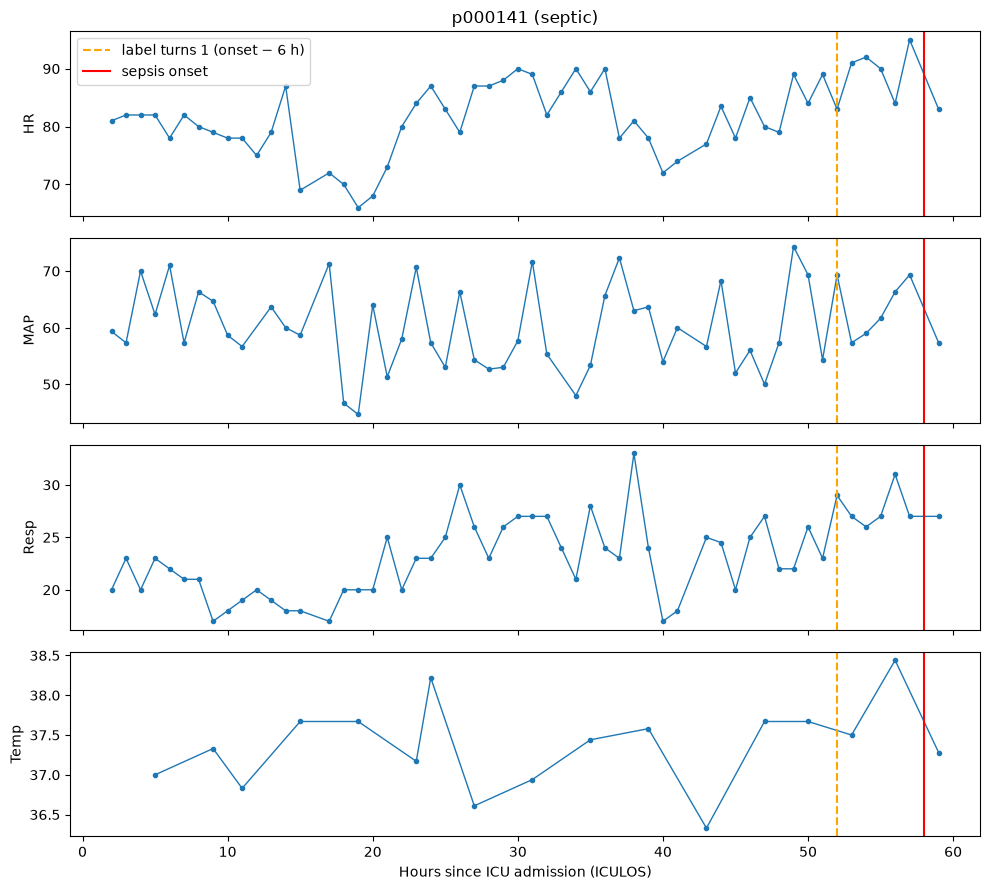

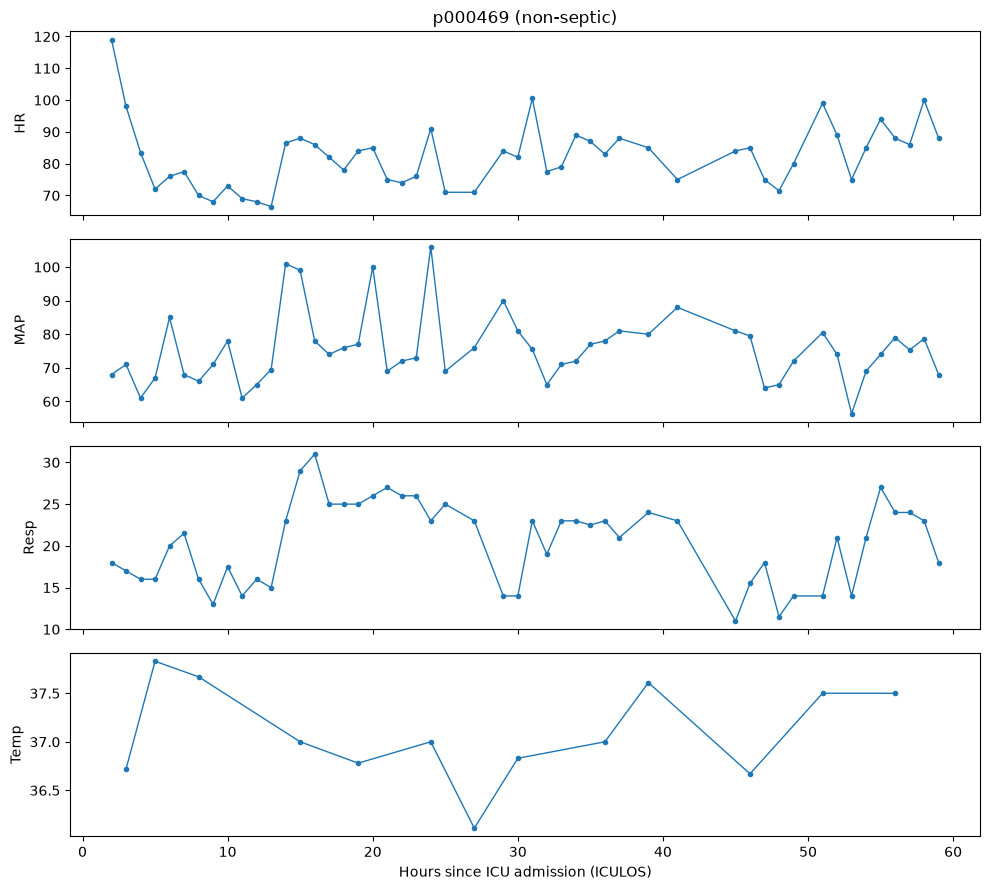

In [8]:
##heart rate (HR), mean arterial pressure (MAP), respiratory rate (Resp), and 
##temperature are the vitals clinicians watch for sepsis: fast heart rate, 
##low blood pressure, fast breathing, and fever (or low temperature)
def plot_vitals(p, title, filename):
    fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
    is_septic = p[LABEL].max() == 1
    if is_septic:
        first = p.loc[p[LABEL] == 1, "ICULOS"].min()

    for ax, col in zip(axes, ["HR", "MAP", "Resp", "Temp"]):
        s = p[["ICULOS", col]].dropna()
        ax.plot(s["ICULOS"], s[col], marker=".", linewidth=1)
        ax.set_ylabel(col)
        if is_septic:
            ax.axvline(first, linestyle="--", color="orange", label="label turns 1 (onset − 6 h)")
            ax.axvline(first + ONSET_SHIFT, color="red", label="sepsis onset")

    axes[0].set_title(title)
    axes[-1].set_xlabel("Hours since ICU admission (ICULOS)")
    if is_septic:
        axes[0].legend(loc="upper left")
    plt.tight_layout()
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

septic_id = "p000141"
nonseptic_id = "p000469"

plot_vitals(frames[septic_id], f"{septic_id} (septic)", f"{septic_id}_septic.png")
plot_vitals(frames[nonseptic_id], f"{nonseptic_id} (non-septic)", f"{nonseptic_id}_nonseptic.png")

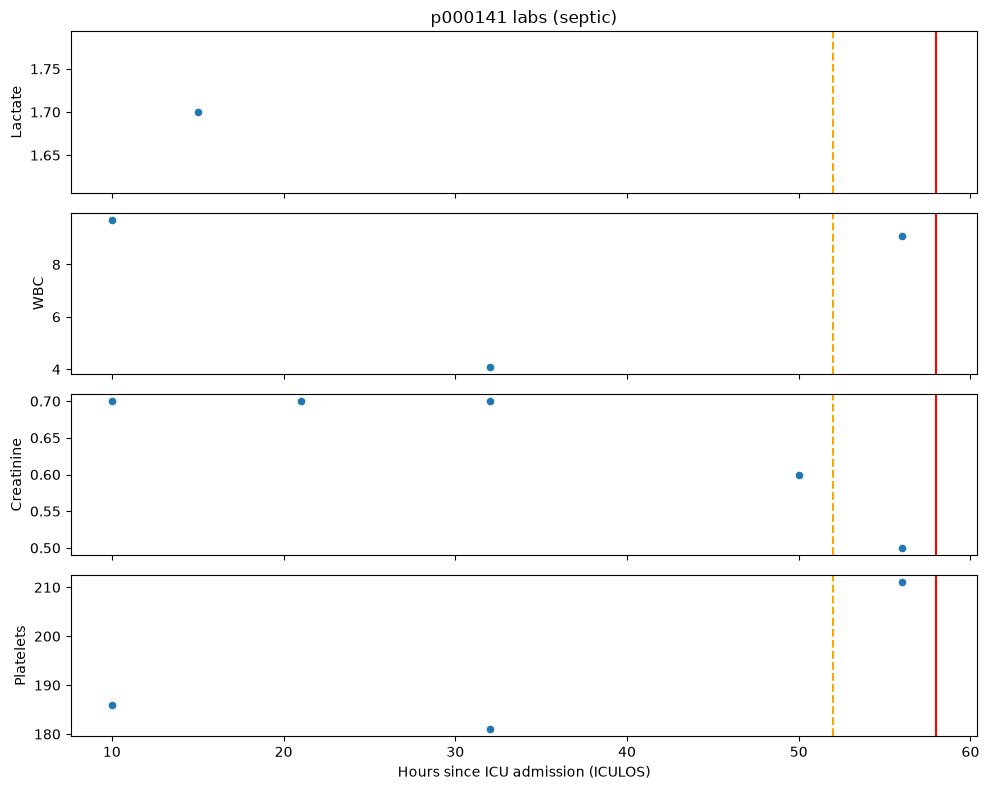

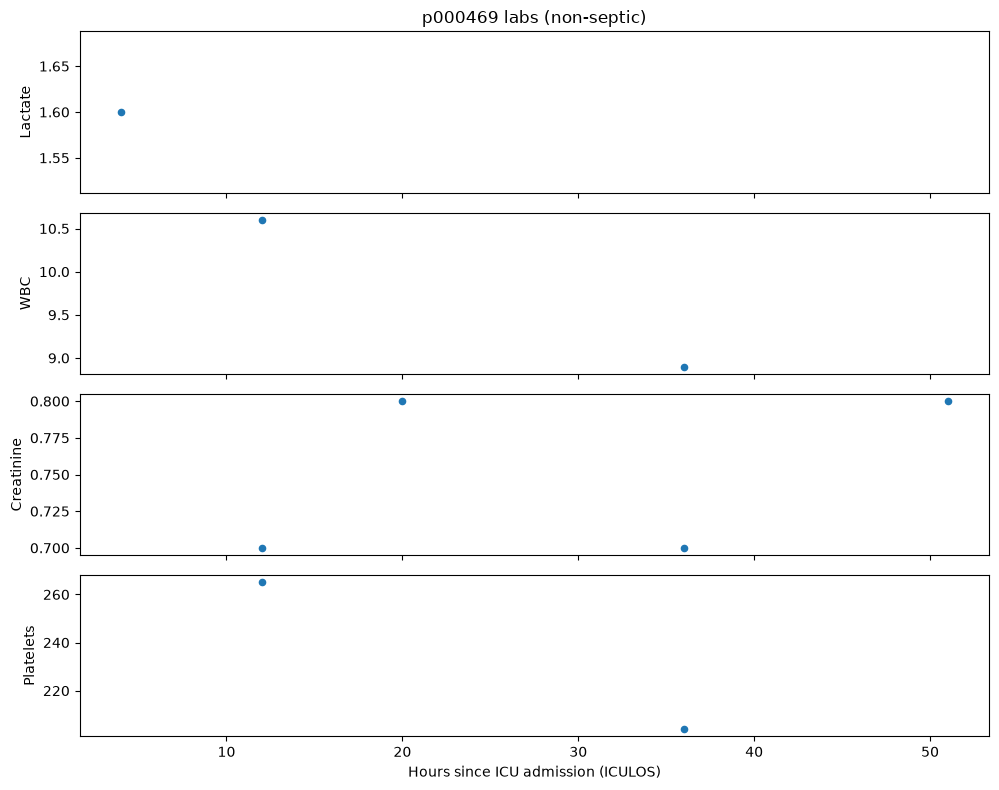

In [9]:
"""these four labs relate to sepsis criteria: lactate (poor tissue oxygenation), white blood cell count (infection), creatinine (kidney stress), and platelets (clotting problems). They’re plotted as dots because they’re measured only occasionally. Look at when they were measured, not just the values: are more tests ordered near onset"""
def plot_labs(p, title, labs=("Lactate", "WBC", "Creatinine", "Platelets")):
    fig, axes = plt.subplots(len(labs), 1, figsize=(10, 8), sharex=True)
    is_septic = p[LABEL].max() == 1
    for ax, col in zip(axes, labs):
        s = p[["ICULOS", col]].dropna()
        ax.scatter(s["ICULOS"], s[col], s=20)      # points, not lines: labs are sparse
        ax.set_ylabel(col)
        if is_septic:
            first = p.loc[p[LABEL] == 1, "ICULOS"].min()
            ax.axvline(first, linestyle="--", color="orange")
            ax.axvline(first + ONSET_SHIFT, color="red")
    axes[0].set_title(title)
    axes[-1].set_xlabel("Hours since ICU admission (ICULOS)")
    plt.tight_layout()
    plt.show()

plot_labs(frames[septic_id], f"{septic_id} labs (septic)")
plot_labs(frames[nonseptic_id], f"{nonseptic_id} labs (non-septic)")

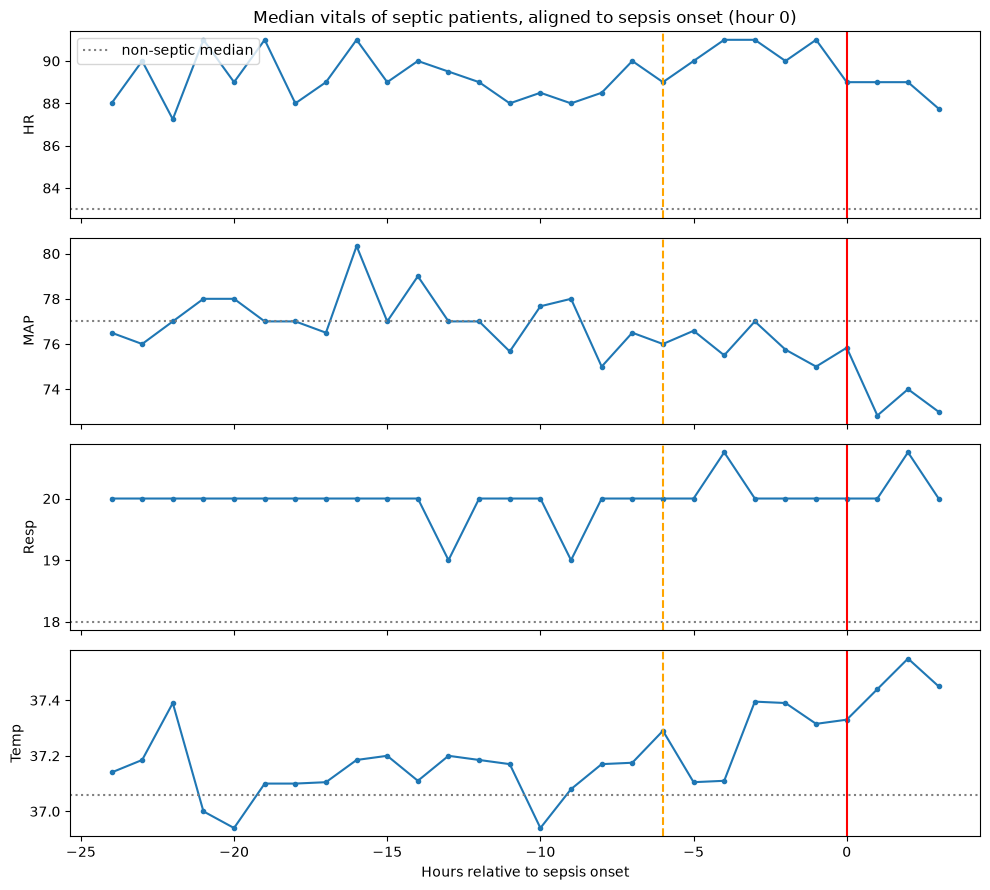

hours_to_onset
-24    111
-23    112
-22    114
-21    118
-20    118
-19    123
-18    123
-17    125
-16    125
-15    127
-14    134
-13    137
-12    139
-11    147
-10    151
-9     154
-8     161
-7     166
-6     184
-5     184
-4     184
-3     184
-2     184
-1     184
 0     184
 1     183
 2     175
 3     114


In [10]:
aligned = []
for pid, p in frames.items():
    if p[LABEL].max() == 1:
        onset = p.loc[p[LABEL] == 1, "ICULOS"].min() + ONSET_SHIFT
        q = p.copy()
        q["hours_to_onset"] = q["ICULOS"] - onset
        aligned.append(q)
aligned = pd.concat(aligned)

window = aligned[aligned["hours_to_onset"].between(-24, 3)]
vitals4 = ["HR", "MAP", "Resp", "Temp"]

trend = window.groupby("hours_to_onset")[vitals4].median()
n_patients = window.groupby("hours_to_onset")["HR"].size()   # how many patients contribute at each hour

nonseptic = pd.concat([p for p in frames.values() if p[LABEL].max() == 0])
baseline = nonseptic[vitals4].median()

fig, axes = plt.subplots(len(vitals4), 1, figsize=(10, 9), sharex=True)
for ax, col in zip(axes, vitals4):
    ax.plot(trend.index, trend[col], marker=".")
    ax.axhline(baseline[col], linestyle=":", color="gray", label="non-septic median")
    ax.axvline(-ONSET_SHIFT, linestyle="--", color="orange")
    ax.axvline(0, color="red")
    ax.set_ylabel(col)
axes[0].legend(loc="upper left")
axes[0].set_title("Median vitals of septic patients, aligned to sepsis onset (hour 0)")
axes[-1].set_xlabel("Hours relative to sepsis onset")
plt.tight_layout()
plt.show()

print(n_patients.to_string())

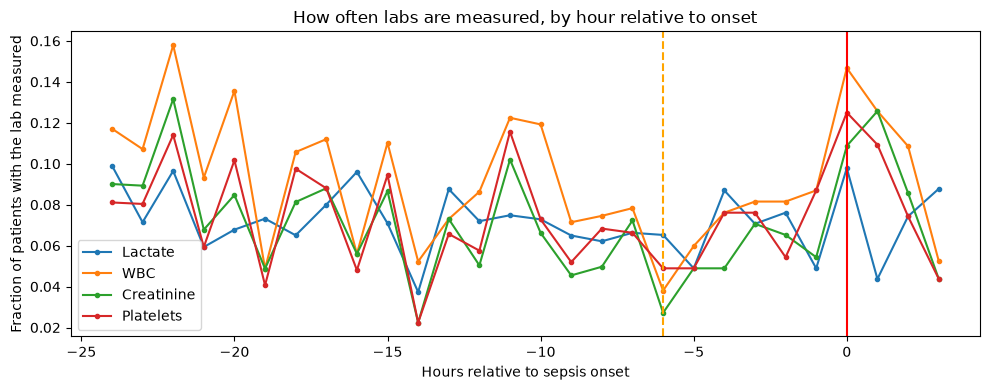

Non-septic patients, fraction of hours with each lab measured:
Lactate       0.031
WBC           0.073
Creatinine    0.065
Platelets     0.064


In [11]:
labs4 = ["Lactate", "WBC", "Creatinine", "Platelets"]

lab_rate = window[labs4].notna().groupby(window["hours_to_onset"]).mean()
nonseptic_rate = nonseptic[labs4].notna().mean()

fig, ax = plt.subplots(figsize=(10, 4))
for col in labs4:
    ax.plot(lab_rate.index, lab_rate[col], marker=".", label=col)
ax.axvline(-ONSET_SHIFT, linestyle="--", color="orange")
ax.axvline(0, color="red")
ax.set_xlabel("Hours relative to sepsis onset")
ax.set_ylabel("Fraction of patients with the lab measured")
ax.set_title("How often labs are measured, by hour relative to onset")
ax.legend()
plt.tight_layout()
plt.show()

print("Non-septic patients, fraction of hours with each lab measured:")
print(nonseptic_rate.round(3).to_string())

## Findings (Part D: visual exploration, first 2,000 Hospital A patients)

**Sample**
- 184 of 2,000 patients septic (9.2%), consistent with the 500-patient estimate
- More records start at ICULOS 2 (p000011, p000171, p000178): a recurring pattern, not a one-off
- Septic records end 9–10 rows after the first label (2–3 h after onset); no gaps in the examples checked (e.g. p000018 and p000188 end after 9 rows)
- Non-septic records max out around 59 h, again consistent with a ~60 h cap

**Individual patients (septic p000141 vs non-septic p000469)**
- Septic: HR rose from ~70s to 85–95 before the label turned on; Resp drifted up over the stay (17–20 → high 20s); MAP persistently low (often < 65); mild fever (38.4 °C) between label and onset
- Non-septic: HR also rose to 85–100 near the end of the stay, so a single trend is not diagnostic
- Vitals are noisy hour to hour (MAP swings 15+ points); temperature is measured only every ~3–4 h

**Labs, individual patients**
- Very sparse: 1–4 values per lab over ~60 h; lactate measured once for each patient
- Values in normal ranges for both patients
- Septic patient had a cluster of labs drawn after the label turned on, before onset

**Onset-aligned medians (all 184 septic patients vs non-septic median)**
| Vital | Septic, 24 h before onset → onset | Non-septic | Pattern |
|---|---|---|---|
| HR | ~88–91 | 83 | Higher level all day; little trend |
| Resp | ~20 | 18 | Higher level all day; no trend |
| MAP | ~77–78 → ~75–76 (→ ~73 after onset) | 77 | Slow downward drift (2–4 points) |
| Temp | ~37.1–37.2, rising to ~37.4 in the last ~4 h | 37.06 | Rise only in the final hours |

- Septic patients look somewhat sicker for the whole day before onset: a level ("who") signal more than a timing ("when") signal
- Resp median is flat partly because values are recorded as whole numbers
- Medians blur individual patients' sharper changes
- Patients contributing: 111 at hour −24 vs 184 at hours −6 to 0, so ~40% of septic patients have < 24 h of data before onset (composition changes along the x-axis)
- Patients labeled 1 from their first hour have uncertain onset (sepsis may have started before ICU admission); exclude them from aligned analyses and likely from the cohort

**Lab measurement rates relative to onset**
- Orders surge at onset (hour 0) and +1: ~10–15% of patients measured, about double the hours before. This reflects clinician suspicion at onset, not early warning
- Before onset, rates rise only mildly, to near non-septic levels (WBC 7.3%, creatinine 6.5%, platelets 6.4% of hours)
- Lactate is measured 2–3× more often in septic patients throughout the 24 h (~6–9% vs 3.1%): a risk-level signal
- Noisy: each point comes from ~110–184 patients; daily lab schedules add periodic swings

**Implications for features**
- Vitals: rolling 6h/12h mean, min, max for HR, MAP, Resp; 6h/12h slopes for HR and Resp
- Within-patient change ("when" signals): deviation from the patient's own baseline; 6h mean minus 24h mean; recent temperature rise; MAP drift
- Clinical thresholds: hours in last 12 with MAP < 65; hours with Resp > 20 and HR > 90; count of warning criteria met now (HR > 90, Resp > 20, Temp > 38 or < 36)
- Sparse vitals and labs: last known value, hours since last measured, change from previous measurement
- Ordering: number of lab draws in the last 12/24 h, lactate-measured flags

**Implications for evaluation**
- Order features may inflate metrics on post-onset hours (0 to +3) through the test surge
- Report performance on pre-onset hours separately, plus lead time before onset and before the first sign of clinician concern
- Day 2 ablations: with vs without ICULOS; with vs without ordering/missingness features